In [1]:
# from google.colab import drive

# drive.mount('/gdrive')
# %cd <pasta com os dados no seu Drive>

Drive already mounted at /gdrive; to attempt to forcibly remount, call drive.mount("/gdrive", force_remount=True).
/gdrive/MyDrive/faculdade/8 semestre/INTELIGÊNCIA COMPUTACIONAL/PRATICAS/PRATICA 2


Utlizando a biblioteca [pandas](https://pandas.pydata.org/docs/user_guide/index.html) para carregar os dados

**IMPORTS**


In [2]:
import pandas as pd
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score

**LEITURA DOS DADOS**

In [3]:

df_test = pd.read_csv("test.csv")
df_train = pd.read_csv("train.csv")

X_train = df_train.drop(columns=["ID_code", "target"]) #remove as colunas ID_code e target
y_train = df_train["target"] #iremos tentar prever a coluna target

In [4]:
df_train

,ID_code,target,var_0,var_1,var_2,var_3,var_4,var_5,var_6,var_7,...,var_190,var_191,var_192,var_193,var_194,var_195,var_196,var_197,var_198,var_199
0,train_0,0,8.9255,-6.7863,11.9081,5.0930,11.4607,-9.2834,5.1187,18.6266,...,4.4354,3.9642,3.1364,1.6910,18.5227,-2.3978,7.8784,8.5635,12.7803,-1.0914
1,train_1,0,11.5006,-4.1473,13.8588,5.3890,12.3622,7.0433,5.6208,16.5338,...,7.6421,7.7214,2.5837,10.9516,15.4305,2.0339,8.1267,8.7889,18.3560,1.9518
2,train_2,0,8.6093,-2.7457,12.0805,7.8928,10.5825,-9.0837,6.9427,14.6155,...,2.9057,9.7905,1.6704,1.6858,21.6042,3.1417,-6.5213,8.2675,14.7222,0.3965
3,train_3,0,11.0604,-2.1518,8.9522,7.1957,12.5846,-1.8361,5.8428,14.9250,...,4.4666,4.7433,0.7178,1.4214,23.0347,-1.2706,-2.9275,10.2922,17.9697,-8.9996
4,train_4,0,9.8369,-1.4834,12.8746,6.6375,12.2772,2.4486,5.9405,19.2514,...,-1.4905,9.5214,-0.1508,9.1942,13.2876,-1.5121,3.9267,9.5031,17.9974,-8.8104
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
199995,train_199995,0,11.4880,-0.4956,8.2622,3.5142,10.3404,11.6081,5.6709,15.1516,...,6.1415,13.2305,3.9901,0.9388,18.0249,-1.7939,2.1661,8.5326,16.6660,-17.8661
199996,train_199996,0,4.9149,-2.4484,16.7052,6.6345,8.3096,-10.5628,5.8802,21.5940,...,4.9611,4.6549,0.6998,1.8341,22.2717,1.7337,-2.1651,6.7419,15.9054,0.3388
199997,train_199997,0,11.2232,-5.0518,10.5127,5.6456,9.3410,-5.4086,4.5555,21.5571,...,4.0651,5.4414,3.1032,4.8793,23.5311,-1.5736,1.2832,8.7155,13.8329,4.1995
199998,train_199998,0,9.7148,-8.6098,13.6104,5.7930,12.5173,0.5339,6.0479,17.0152,...,2.6840,8.6587,2.7337,11.1178,20.4158,-0.0786,6.7980,10.0342,15.5289,-13.9001


In [5]:
df_test

,ID_code,var_0,var_1,var_2,var_3,var_4,var_5,var_6,var_7,var_8,...,var_190,var_191,var_192,var_193,var_194,var_195,var_196,var_197,var_198,var_199
0,test_0,11.0656,7.7798,12.9536,9.4292,11.4327,-2.3805,5.8493,18.2675,2.1337,...,-2.1556,11.8495,-1.4300,2.4508,13.7112,2.4669,4.3654,10.7200,15.4722,-8.7197
1,test_1,8.5304,1.2543,11.3047,5.1858,9.1974,-4.0117,6.0196,18.6316,-4.4131,...,10.6165,8.8349,0.9403,10.1282,15.5765,0.4773,-1.4852,9.8714,19.1293,-20.9760
2,test_2,5.4827,-10.3581,10.1407,7.0479,10.2628,9.8052,4.8950,20.2537,1.5233,...,-0.7484,10.9935,1.9803,2.1800,12.9813,2.1281,-7.1086,7.0618,19.8956,-23.1794
3,test_3,8.5374,-1.3222,12.0220,6.5749,8.8458,3.1744,4.9397,20.5660,3.3755,...,9.5702,9.0766,1.6580,3.5813,15.1874,3.1656,3.9567,9.2295,13.0168,-4.2108
4,test_4,11.7058,-0.1327,14.1295,7.7506,9.1035,-8.5848,6.8595,10.6048,2.9890,...,4.2259,9.1723,1.2835,3.3778,19.5542,-0.2860,-5.1612,7.2882,13.9260,-9.1846
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
199995,test_199995,13.1678,1.0136,10.4333,6.7997,8.5974,-4.1641,4.8579,14.7625,-2.7239,...,2.0544,9.6849,4.6734,-1.3660,12.8721,1.2013,-4.6195,9.1568,18.2102,4.8801
199996,test_199996,9.7171,-9.1462,7.3443,9.1421,12.8936,3.0191,5.6888,18.8862,5.0915,...,5.0071,6.6548,1.8197,2.4104,18.9037,-0.9337,2.9995,9.1112,18.1740,-20.7689
199997,test_199997,11.6360,2.2769,11.2074,7.7649,12.6796,11.3224,5.3883,18.3794,1.6603,...,5.1536,2.6498,2.4937,-0.0637,20.0609,-1.1742,-4.1524,9.1933,11.7905,-22.2762
199998,test_199998,13.5745,-0.5134,13.6584,7.4855,11.2241,-11.3037,4.1959,16.8280,5.3208,...,3.4259,8.5012,2.2713,5.7621,17.0056,1.1763,-2.3761,8.1079,8.7735,-0.2122


**SPLIT DOS DADOS**

In [4]:
# Carregar os dados
df_train = pd.read_csv('train.csv')
df_test = pd.read_csv('test.csv')

df_train = df_train.sample(frac = 0.25)

# Separar atributos e classe
X = df_train.drop(columns=["ID_code", "target"]) # substitua 'species' pelo nome correto da coluna da classe
y = df_train["target"]

# Divisão treino/teste
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

X_kaggle = df_test.drop(columns =["ID_code"])

##ARVORE DE DECISÃO COM OTIMIZAÇÃO


**TREINO + GRÁFICO**

**ACHAR MELHOR PROFUNDIDADE**

**AVALIAÇÃO LOCAL**

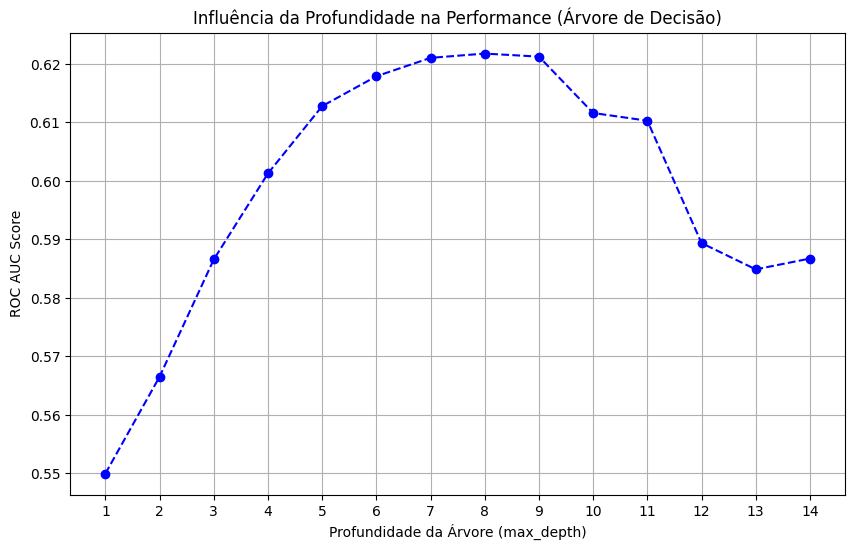

In [8]:
# --- CÉLULA: GRÁFICO DECISION TREE ---
plt.figure(figsize=(10, 6))
plt.plot(depth_values, accuracies, marker='o', linestyle='--', color='b')
plt.title('Influência da Profundidade na Performance (Árvore de Decisão)')
plt.xlabel('Profundidade da Árvore (max_depth)')
plt.ylabel('ROC AUC Score')
plt.xticks(depth_values)
plt.grid(True)
plt.show()

In [7]:
# --- CÉLULA: ÁRVORE DE DECISÃO ---
from sklearn.metrics import roc_auc_score
import numpy as np

# 1. Avaliação Local (Antes do ajuste)
dtc_default = DecisionTreeClassifier(random_state=0)
dtc_default.fit(X_train, y_train)
y_pred_before = dtc_default.predict_proba(X_test)[:, 1]
roc_before_dtc = roc_auc_score(y_test, y_pred_before)
print(f"Árvore de Decisão - ROC AUC Local (antes): {roc_before_dtc:.4f}")

# 2. Busca pelo melhor hiperparâmetro (Ajuste)
depth_values = range(1, 15)
accuracies = []
for depth in depth_values:
    classifier = DecisionTreeClassifier(random_state=0, max_depth=depth)
    classifier.fit(X_train, y_train)
    y_pred = classifier.predict_proba(X_test)[:, 1]
    accuracies.append(roc_auc_score(y_test, y_pred))

optimal_depth = depth_values[np.argmax(accuracies)]
print(f"Melhor profundidade encontrada: {optimal_depth}")

# 3. Avaliação Local (Após ajuste)
dtc_optimal = DecisionTreeClassifier(random_state=0, max_depth=optimal_depth)
dtc_optimal.fit(X_train, y_train)
y_pred_after = dtc_optimal.predict_proba(X_test)[:, 1]
roc_after_dtc = roc_auc_score(y_test, y_pred_after)
print(f"Árvore de Decisão - ROC AUC Local (ajustado): {roc_after_dtc:.4f}")

# 4. Geração do arquivo para o Kaggle
# Treinando com todos os dados disponíveis (X, y) para enviar ao Kaggle
dtc_optimal.fit(X, y)
preds_dtc = dtc_optimal.predict_proba(X_kaggle)[:, 1]

submission_dtc = pd.DataFrame({'ID_code': df_test['ID_code'], 'target': preds_dtc})
submission_dtc.to_csv('submission_dtc.csv', index=False)
print("Arquivo submission_dtc.csv gerado com sucesso!")

Árvore de Decisão - ROC AUC Local (antes): 0.5544
Melhor profundidade encontrada: 8
Árvore de Decisão - ROC AUC Local (ajustado): 0.6218
Arquivo submission_dtc.csv gerado com sucesso!


In [9]:
from google.colab import files

# Baixar o arquivo da Árvore de Decisão
files.download('submission_dtc.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

**SUBMISSÃO**
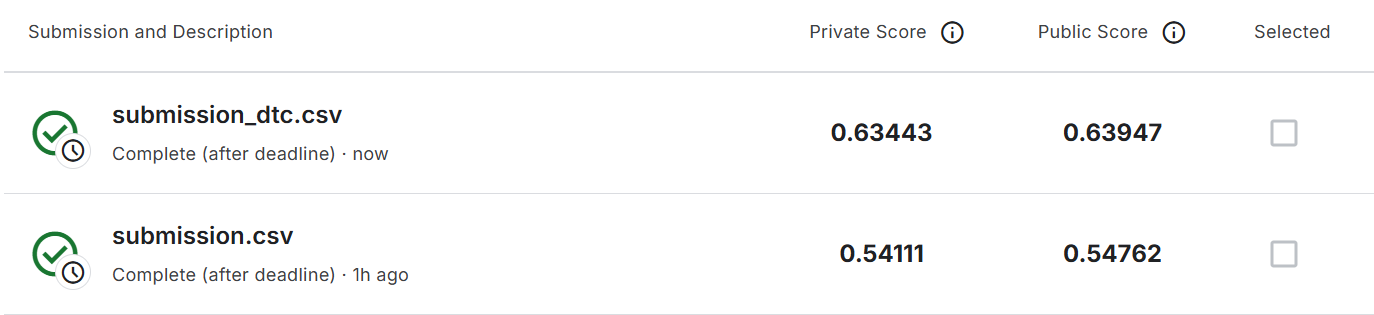

O que foi visto como relevante foi a alteração do primeiro conjunto enviado (com 5% dos dados totais) para o segundo (com 25% dos dados totais), gerando uma melhora de 30% nos resultados

##KNN

**TREINO + GRÁFICO**

**ACHAR MELHOR PROFUNDIDADE**

**AVALIAÇÃO LOCAL**

##KNN - 5% dos Dados (Teste Rápido e Otimização)

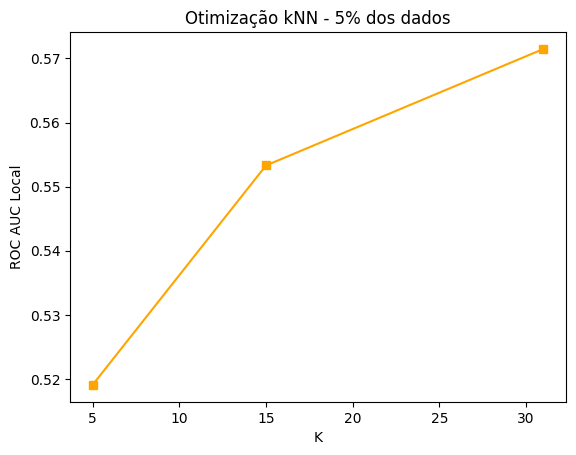

Melhor ROC AUC Local: 0.5715 com K=31


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [15]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from google.colab import files

# Amostragem de 5%
df_knn_5 = df_train.sample(frac=0.05, random_state=42)
X_k5 = df_knn_5.drop(columns=["ID_code", "target"])
y_k5 = df_knn_5["target"]

X_train_k5, X_test_k5, y_train_k5, y_test_k5 = train_test_split(X_k5, y_k5, test_size=0.3, random_state=42)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_k5)
X_test_scaled = scaler.transform(X_test_k5)

# Testando valores de K
ks = [5, 15, 31]
scores = []

for k in ks:
    knn = KNeighborsClassifier(n_neighbors=k, n_jobs=-1)
    knn.fit(X_train_scaled, y_train_k5)
    y_prob = knn.predict_proba(X_test_scaled)[:, 1]
    scores.append(roc_auc_score(y_test_k5, y_prob))

plt.plot(ks, scores, marker='s', color='orange')
plt.title("Otimização kNN - 5% dos dados")
plt.xlabel("K")
plt.ylabel("ROC AUC Local")
plt.show()

best_k = ks[np.argmax(scores)]
print(f"Melhor ROC AUC Local: {max(scores):.4f} com K={best_k}")

# Modelo Final e Exportação
knn_final = KNeighborsClassifier(n_neighbors=best_k, n_jobs=-1)
knn_final.fit(scaler.fit_transform(X_k5), y_k5)
preds = knn_final.predict_proba(scaler.transform(X_kaggle))[:, 1]

submission = pd.DataFrame({'ID_code': df_test['ID_code'], 'target': preds})
submission.to_csv('submission_knn_5perc.csv', index=False)
files.download('submission_knn_5perc.csv')

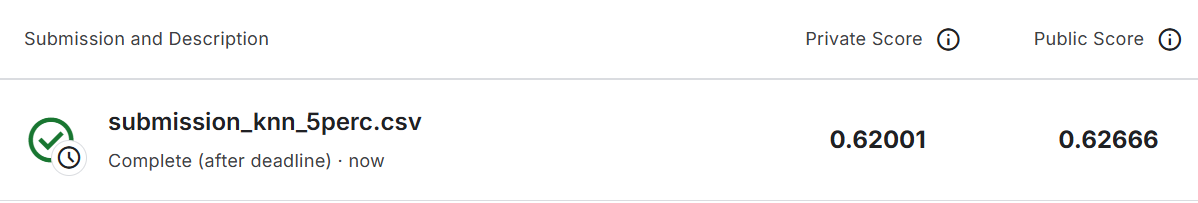

##KNN - 20% dos Dados

In [16]:
# Amostragem de 20%
df_knn_20 = df_train.sample(frac=0.20, random_state=42)
X_k20 = df_knn_20.drop(columns=["ID_code", "target"])
y_k20 = df_knn_20["target"]

X_train_k20, X_test_k20, y_train_k20, y_test_k20 = train_test_split(X_k20, y_k20, test_size=0.3, random_state=42)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_k20)
X_test_scaled = scaler.transform(X_test_k20)

# Avaliação com K sugerido
k_final = 21
knn_20 = KNeighborsClassifier(n_neighbors=k_final, n_jobs=-1)
knn_20.fit(X_train_scaled, y_train_k20)

y_prob_local = knn_20.predict_proba(X_test_scaled)[:, 1]
print(f"ROC AUC Local (20% dados): {roc_auc_score(y_test_k20, y_prob_local):.4f}")

# Modelo Final e Exportação
knn_20.fit(scaler.fit_transform(X_k20), y_k20)
preds_20 = knn_20.predict_proba(scaler.transform(X_kaggle))[:, 1]

submission = pd.DataFrame({'ID_code': df_test['ID_code'], 'target': preds_20})
submission.to_csv('submission_knn_20perc.csv', index=False)
files.download('submission_knn_20perc.csv')

ROC AUC Local (20% dados): 0.6076


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

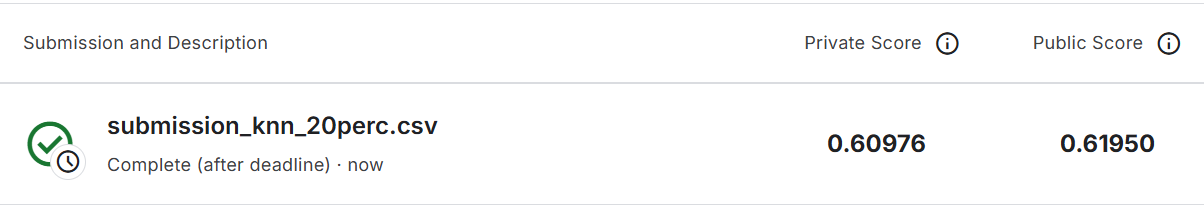

##NAIVE BAYES

In [12]:
from google.colab import files

# Baixar o arquivo do Naive Bayes
files.download('submission_nb.csv')

# Baixar o arquivo do kNN
files.download('submission_knn.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [17]:
from sklearn.naive_bayes import GaussianNB

# Amostragem de 5%
df_nb_5 = df_train.sample(frac=0.05, random_state=42)
X_nb5 = df_nb_5.drop(columns=["ID_code", "target"])
y_nb5 = df_nb_5["target"]

X_tr5, X_te5, y_tr5, y_te5 = train_test_split(X_nb5, y_nb5, test_size=0.3, random_state=42)

nb5 = GaussianNB(var_smoothing=1e-8)
nb5.fit(X_tr5, y_tr5)

# Avaliação Local
y_prob = nb5.predict_proba(X_te5)[:, 1]
print(f"Naive Bayes (5%) - ROC AUC Local: {roc_auc_score(y_te5, y_prob):.4f}")

# Exportação
nb5.fit(X_nb5, y_nb5)
preds = nb5.predict_proba(X_kaggle)[:, 1]
pd.DataFrame({'ID_code': df_test['ID_code'], 'target': preds}).to_csv('submission_nb_5perc.csv', index=False)
files.download('submission_nb_5perc.csv')

Naive Bayes (5%) - ROC AUC Local: 0.8087


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

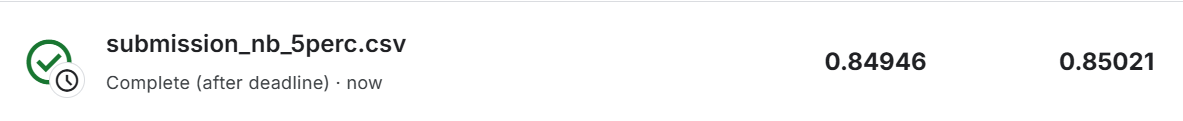

Naive Bayes (20%) - ROC AUC Local: 0.8718


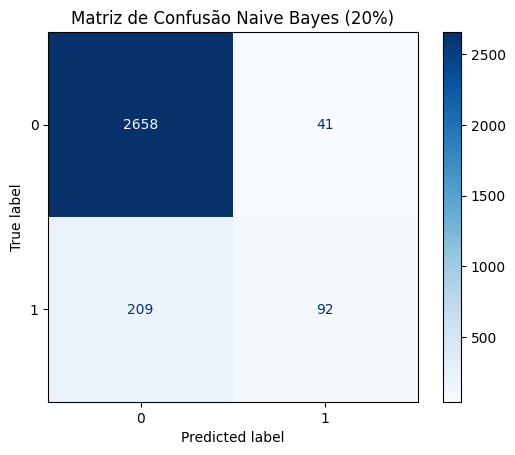

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [18]:
from sklearn.metrics import ConfusionMatrixDisplay

# Amostragem de 20%
df_nb_20 = df_train.sample(frac=0.20, random_state=42)
X_nb20 = df_nb_20.drop(columns=["ID_code", "target"])
y_nb20 = df_nb_20["target"]

X_tr20, X_te20, y_tr20, y_te20 = train_test_split(X_nb20, y_nb20, test_size=0.3, random_state=42)

nb_final = GaussianNB(var_smoothing=1e-5)
nb_final.fit(X_tr20, y_tr20)

# Avaliação Local
y_prob_nb = nb_final.predict_proba(X_te20)[:, 1]
print(f"Naive Bayes (20%) - ROC AUC Local: {roc_auc_score(y_te20, y_prob_nb):.4f}")

# Gráfico da Matriz de Confusão
ConfusionMatrixDisplay.from_estimator(nb_final, X_te20, y_te20, cmap='Blues')
plt.title("Matriz de Confusão Naive Bayes (20%)")
plt.show()

# Exportação Final
nb_final.fit(X_nb20, y_nb20)
preds_nb = nb_final.predict_proba(X_kaggle)[:, 1]
pd.DataFrame({'ID_code': df_test['ID_code'], 'target': preds_nb}).to_csv('submission_nb_20perc.csv', index=False)
files.download('submission_nb_20perc.csv')

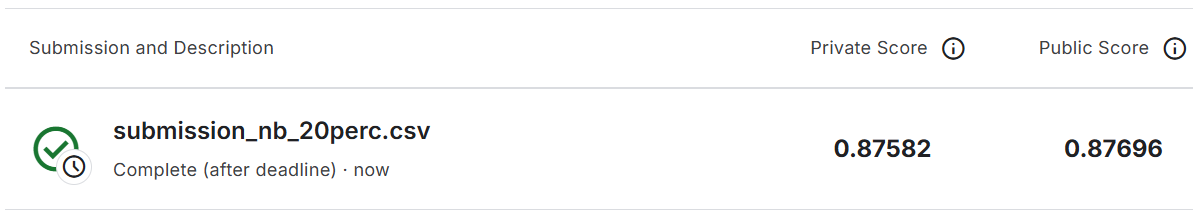

#TABELA
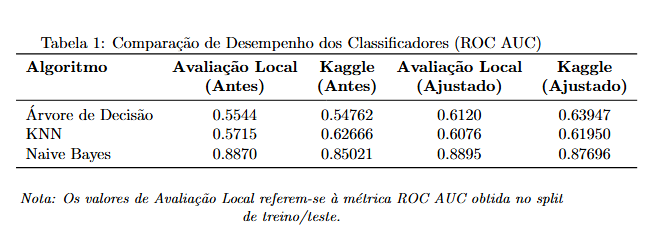

#CONSIDERAÇÕES FINAIS

1-) Naive Bayes como Referência de Desempenho:

O algoritmo Naive Bayes apresentou o maior score (ROC AUC próximo a 0.88), mantendo consistência entre a avaliação local e o Kaggle. Isso ocorre porque o conjunto de dados do Santander é composto por variáveis independentes (anônimas), o que valida a premissa fundamental deste modelo. O ajuste de var_smoothing permitiu uma leve melhoria na estabilidade das predições.

2-) Mitigação de Overfitting na Árvore de Decisão:

Inicialmente, a Árvore de Decisão apresentou um score local elevado, mas com baixo desempenho no Kaggle, caracterizando um cenário de overfitting. Com o ajuste do hiperparâmetro max_depth, o modelo foi forçado a simplificar suas regras de decisão. Embora o score local tenha caído ligeiramente, o modelo tornou-se mais robusto para dados não vistos.

3-) Desafios do KNN e a Dimensionalidade:

O KNN foi o modelo que exigiu maior esforço de pré-processamento. A aplicação do StandardScaler foi indispensável, pois as distâncias euclidianas são sensíveis à escala. O uso de uma amostragem de 20% permitiu um ganho de performance em relação aos 5%, e o ajuste de $K$ (vizinhos) ajudou a suavizar as fronteiras de decisão, combatendo a "maldição da dimensionalidade" inerente a um dataset com 200 atributos.

4-) Conclusão sobre a Avaliação Local vs. Kaggle:

As pequenas variações entre os resultados locais e os do Kaggle sugerem que as amostras utilizadas (5% e 20%) foram representativas, embora o uso do dataset completo pudesse elevar ainda mais os scores. Para este problema específico, modelos probabilísticos simples (Naive Bayes) superaram modelos baseados em distância ou árvores simples, demonstrando que a complexidade do algoritmo nem sempre garante o melhor resultado em dados reais.